# AI Inventory & Replenishment Planner
## Milestone 2: Model Implementation and Testing (H&M dataset)

<a href="https://colab.research.google.com/github/QuantumFluxx-pew/AI-Inventory-Replenishment-Planner/blob/main/notebooks/AI_Inventory_Replenishment_Planner_HM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Project Overview
This project builds an AI-assisted inventory planning system that forecasts product demand, decides
when to reorder, and how much to order. A conversational agent (Streamlit app) calls these models
as tools and explains the results.

### 2. Objectives
- Forecast daily demand with a **Simple Moving Average (SMA)** and measure accuracy with **MAE**.
- Calculate the order quantity with the **Economic Order Quantity (EOQ)**.
- Decide when to reorder with the **Reorder Point (ROP)**.
- Test the models under increased demand, longer lead times and invalid inputs.

### 3. Tools
Google Colab · Python · pandas · NumPy · Matplotlib · Streamlit (dashboard + agent) · H&M dataset.

### 4. Dataset: H&M Personalized Fashion Recommendations (Kaggle)
The full dataset has **31 million purchases** of 105,000 H&M products (2018-2020), with real product
names and a photo of every product.

**How the 18 products were selected** (too large to load in Colab, so this ran on Kaggle):
1. `kaggle/hm_select_products.py` read all purchases from the last 365 days (2019-09-24 to 2020-09-22)
   and counted **units sold per product per day**.
2. It kept products sold on at least **90% of days** and ranked them by forecastability
   (MAE of a 7-day SMA divided by average demand). The top 40 were saved with their photos.
3. `prepare_data.py` then **cleaned** them: checked for gaps, negatives and duplicates, removed
   products **being phased out** (last 4 weeks below 50% of their yearly average), and kept at most
   3 per product type so the mix is varied. **18 products** remain.

**Limitations (clearly labelled assumptions):** H&M does not publish stock levels, supplier lead
times or costs. **Current stock is simulated** (fixed random seed), and ordering cost, holding cost
and lead time are sample assumptions.

### 5. Load the data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

# Read from the GitHub repository (works in Colab); use local files if they exist.
REPO = "https://raw.githubusercontent.com/QuantumFluxx-pew/AI-Inventory-Replenishment-Planner/main"
LOCAL = ".." if os.path.exists("../data/products.csv") else "."
BASE = LOCAL if os.path.exists(f"{LOCAL}/data/products.csv") else REPO

products = pd.read_csv(f"{BASE}/data/products.csv", dtype={"Product_ID": str})
sales_long = pd.read_csv(f"{BASE}/data/daily_sales.csv", dtype={"article_id": str}, parse_dates=["date"])

print("Products:", products.shape, " Daily sales rows:", sales_long.shape)
print("Dates:", sales_long.date.min().date(), "to", sales_long.date.max().date())

Products: (18, 7)  Daily sales rows: (6570, 3)
Dates: 2019-09-24 to 2020-09-22


### 6. Preview the products (real names and photos)

In [2]:
cards = "".join(
    f'<div style="display:inline-block;width:120px;margin:4px;text-align:center;font-size:11px">'
    f'<img src="{REPO}/images/{pid}.jpg" style="width:110px"><br>{name}</div>'
    for pid, name in zip(products.Product_ID, products.Name))
display(HTML(cards))
display(products[["Product_ID", "Name", "Product_Type", "Colour", "Current_Stock"]])

,Product_ID,Name,Product_Type,Colour,Current_Stock
0,0372860002,7p Basic Shaftless,Socks,White,336
1,0751471001,Pluto RW slacks (1),Trousers,Black,522
2,0783346001,Primo slacks,Trousers,Black,351
3,0579541001,Calista cardigan,Cardigan,Black,322
4,0752814003,Milk RW slack,Trousers,Black,47
5,0673396002,Ringo hipbelt,Belt,Black,271
6,0723469001,Kelly 2pk Melbourne push ct,Bra,Black,132
7,0768912001,Long leggings update,Leggings/Tights,Black,363
8,0762846006,Lucy blouse,Shirt,Black,180
9,0624486001,Brit Baby Tee,T-shirt,Black,65


### 7. Data quality checks

In [3]:
sales = sales_long.pivot(index="date", columns="article_id", values="units")

checks = {
    "one row per day (no missing dates)": len(sales) == (sales.index.max() - sales.index.min()).days + 1,
    "no missing values": not sales.isna().any().any(),
    "no negative sales": (sales >= 0).all().all(),
    "no duplicate (date, product) rows": not sales_long.duplicated(["date", "article_id"]).any(),
    "every product has sales history": set(products.Product_ID) <= set(sales.columns),
    "sold on at least 90% of days": ((sales > 0).mean() >= 0.9).all(),
}
for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
assert all(checks.values())

PASS  one row per day (no missing dates)
PASS  no missing values
PASS  no negative sales
PASS  no duplicate (date, product) rows
PASS  every product has sales history
PASS  sold on at least 90% of days


### 8. Simple Moving Average (SMA) forecast
The forecast for tomorrow is the **average of the last 7 days** of sales:
$$ d = \frac{1}{7}\sum_{t-6}^{t} \text{sales} $$

In [4]:
WINDOW = 7
products["SMA_7"] = [sales[pid].tail(WINDOW).mean() for pid in products.Product_ID]
products[["Name", "SMA_7"]].round(2)

,Name,SMA_7
0,7p Basic Shaftless,33.71
1,Pluto RW slacks (1),75.14
2,Primo slacks,32.71
3,Calista cardigan,34.71
4,Milk RW slack,12.29
5,Ringo hipbelt,23.00
6,Kelly 2pk Melbourne push ct,13.43
7,Long leggings update,36.00
8,Lucy blouse,43.43
9,Brit Baby Tee,9.29


### 9. Visualize sales vs. the SMA forecast

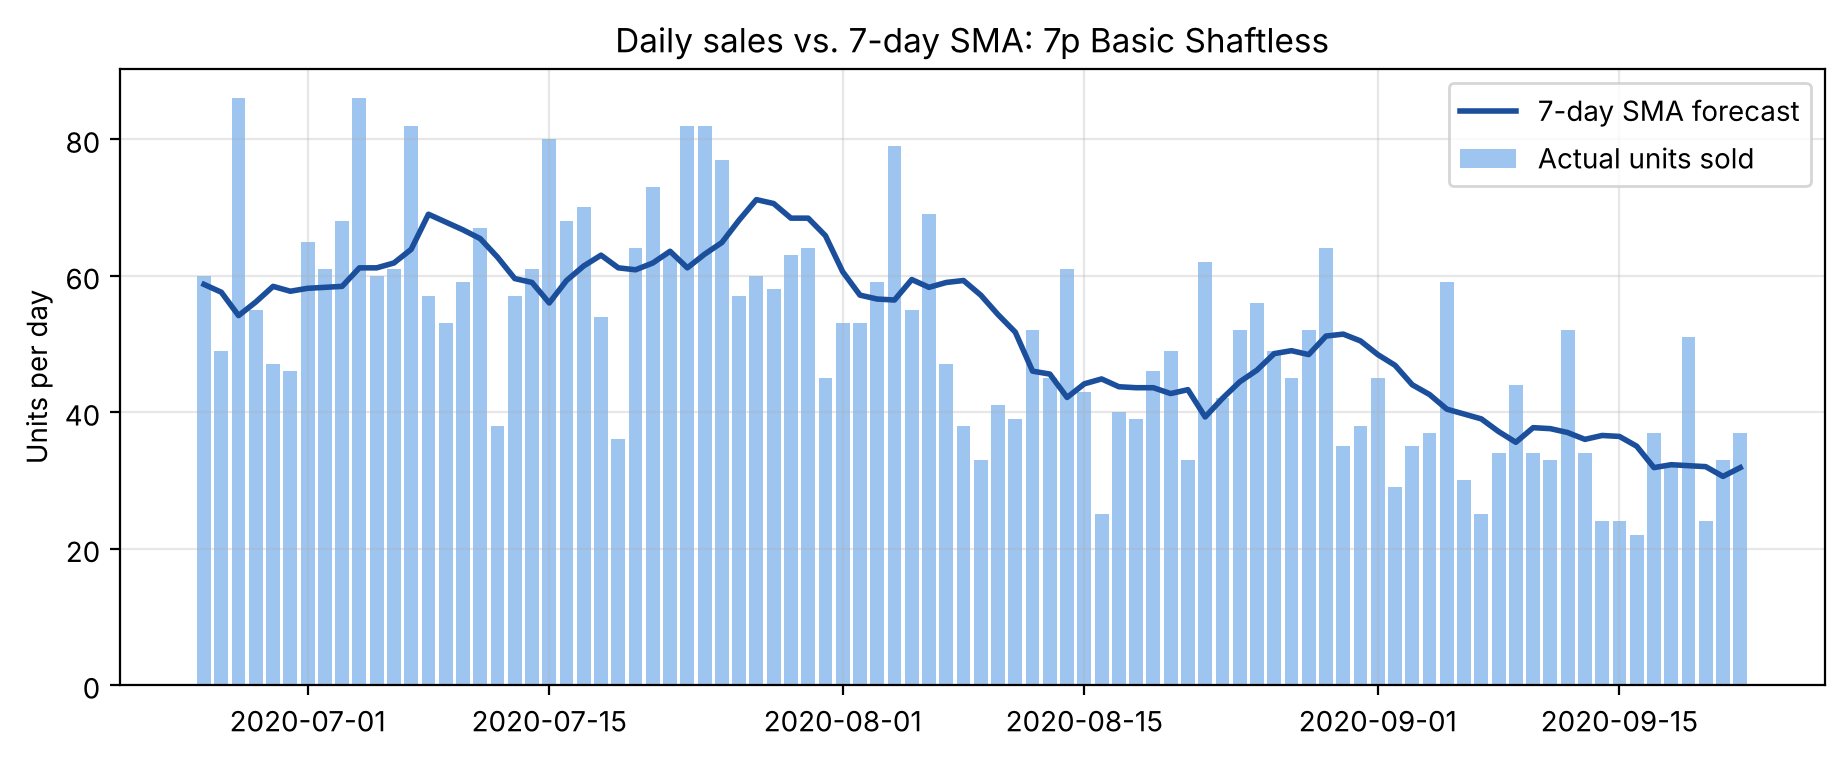

In [5]:
pid = products.Product_ID.iloc[0]
s = sales[pid].tail(90)
forecast = sales[pid].shift(1).rolling(WINDOW).mean().tail(90)   # one-day-ahead forecast

plt.figure(figsize=(11, 4))
plt.bar(s.index, s.values, color="#9ec5f0", label="Actual units sold")
plt.plot(forecast.index, forecast.values, color="#1b4f9c", linewidth=2, label="7-day SMA forecast")
plt.title("Daily sales vs. 7-day SMA: " + products.Name.iloc[0])
plt.ylabel("Units per day"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### 10. Forecast accuracy (MAE) and the best window
For every day we forecast with the average of the previous N days, then average the absolute errors.
We compare N = 3, 7, 14 and 28 days. **Scaled MAE** = MAE ÷ average daily demand, so products of
different sizes can be compared.

In [6]:
def sma_mae(series, window):
    pred = series.shift(1).rolling(window).mean()
    return (series - pred).abs().mean()

rows = []
for pid, name in zip(products.Product_ID, products.Name):
    for w in (3, 7, 14, 28):
        mae = sma_mae(sales[pid], w)
        rows.append({"Name": name, "window": w, "MAE": mae, "scaled_MAE": mae / sales[pid].mean()})
accuracy = pd.DataFrame(rows)

print("Median scaled MAE by window (lower is better):")
print(accuracy.groupby("window").scaled_MAE.median().round(3))
products["MAE"] = [sma_mae(sales[pid], WINDOW) for pid in products.Product_ID]

Median scaled MAE by window (lower is better):
window
3     0.366
7     0.350
14    0.381
28    0.412
Name: scaled_MAE, dtype: float64


### 11. Economic Order Quantity (EOQ)
$$ EOQ = \sqrt{\frac{2DS}{H}} $$
D = annual demand (SMA × 365), S = $50 per order, H = $2 per unit per year (**assumptions**).
EOQ is rounded **up** to whole units.

In [7]:
ORDER_COST, HOLDING_COST = 50, 2
products["Annual_Demand"] = products.SMA_7 * 365
products["EOQ"] = np.ceil(np.round(np.sqrt(2 * products.Annual_Demand * ORDER_COST / HOLDING_COST), 9)).astype(int)
products[["Name", "SMA_7", "Annual_Demand", "EOQ"]].round(2)

,Name,SMA_7,Annual_Demand,EOQ
0,7p Basic Shaftless,33.71,12305.71,785
1,Pluto RW slacks (1),75.14,27427.14,1172
2,Primo slacks,32.71,11940.71,773
3,Calista cardigan,34.71,12670.71,796
4,Milk RW slack,12.29,4484.29,474
5,Ringo hipbelt,23.00,8395.00,648
6,Kelly 2pk Melbourne push ct,13.43,4901.43,496
7,Long leggings update,36.00,13140.00,811
8,Lucy blouse,43.43,15851.43,891
9,Brit Baby Tee,9.29,3389.29,412


### 12. Reorder Point (ROP)
$$ ROP = d \times L $$
d = forecast daily demand, L = **7-day** supplier lead time (assumption). No safety stock in the base model.

In [8]:
LEAD_TIME = 7
products["ROP"] = np.ceil(np.round(products.SMA_7 * LEAD_TIME, 9)).astype(int)
products[["Name", "SMA_7", "ROP", "EOQ"]].round(2)

,Name,SMA_7,ROP,EOQ
0,7p Basic Shaftless,33.71,236,785
1,Pluto RW slacks (1),75.14,526,1172
2,Primo slacks,32.71,229,773
3,Calista cardigan,34.71,243,796
4,Milk RW slack,12.29,86,474
5,Ringo hipbelt,23.00,161,648
6,Kelly 2pk Melbourne push ct,13.43,94,496
7,Long leggings update,36.00,252,811
8,Lucy blouse,43.43,304,891
9,Brit Baby Tee,9.29,65,412


### 13. Replenishment recommendations
Reorder EOQ units when **current stock ≤ ROP**. Current stock is **simulated**.

In [9]:
products["Status"] = np.where(products.Current_Stock <= products.ROP, "Reorder", "Sufficient Stock")
products["Order_Quantity"] = np.where(products.Status == "Reorder", products.EOQ, 0)
products["Days_of_Cover"] = (products.Current_Stock / products.SMA_7).round(1)

display(products[["Name", "Current_Stock", "ROP", "EOQ", "Days_of_Cover", "Status", "Order_Quantity"]])
print("Products needing reorder:", (products.Status == "Reorder").sum(),
      "| Units to order:", products.Order_Quantity.sum())

,Name,Current_Stock,ROP,EOQ,Days_of_Cover,Status,Order_Quantity
0,7p Basic Shaftless,336,236,785,10.0,Sufficient Stock,0
1,Pluto RW slacks (1),522,526,1172,6.9,Reorder,1172
2,Primo slacks,351,229,773,10.7,Sufficient Stock,0
3,Calista cardigan,322,243,796,9.3,Sufficient Stock,0
4,Milk RW slack,47,86,474,3.8,Reorder,474
5,Ringo hipbelt,271,161,648,11.8,Sufficient Stock,0
6,Kelly 2pk Melbourne push ct,132,94,496,9.8,Sufficient Stock,0
7,Long leggings update,363,252,811,10.1,Sufficient Stock,0
8,Lucy blouse,180,304,891,4.1,Reorder,891
9,Brit Baby Tee,65,65,412,7.0,Reorder,412


Products needing reorder: 8 | Units to order: 5048


### 14. Visualize replenishment status

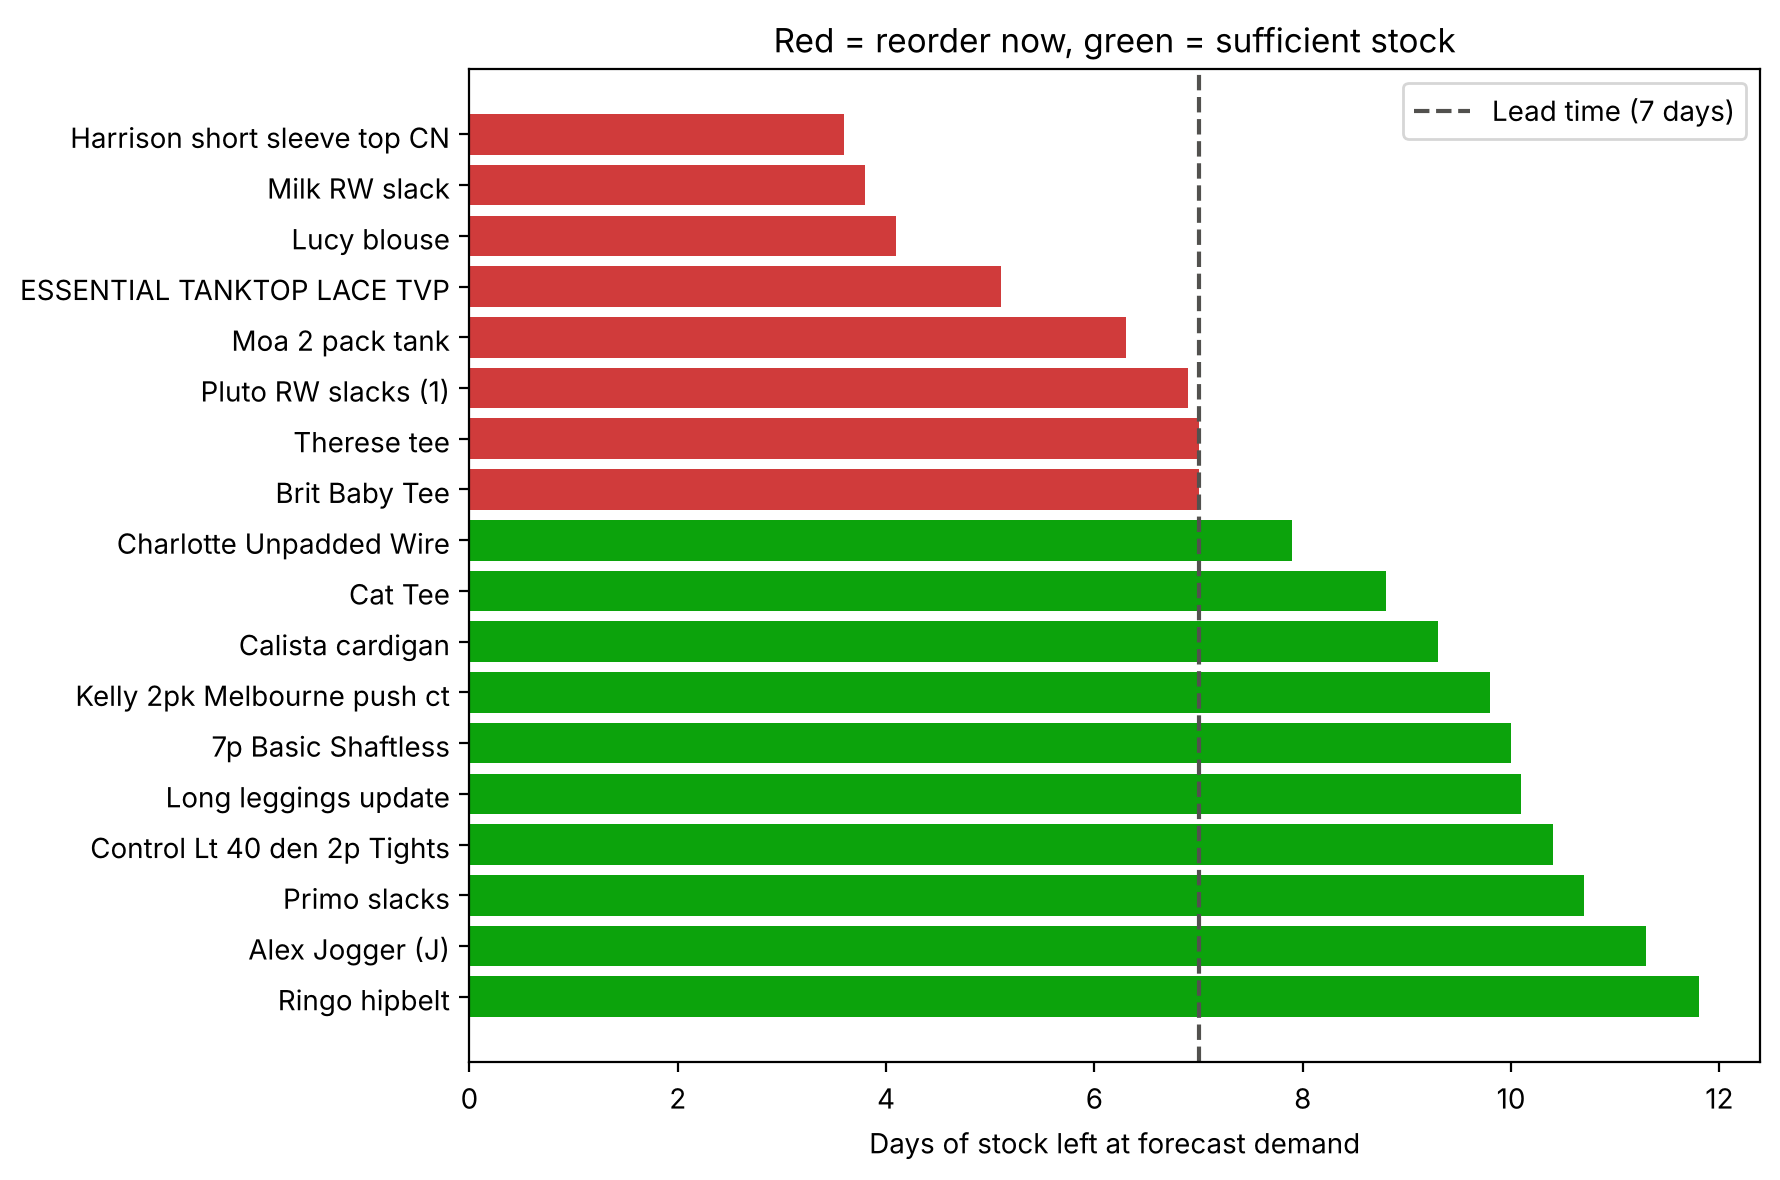

In [10]:
plot = products.sort_values("Days_of_Cover")
colors = np.where(plot.Status == "Reorder", "#d03b3b", "#0ca30c")
plt.figure(figsize=(9, 6))
plt.barh(plot.Name, plot.Days_of_Cover, color=colors)
plt.axvline(LEAD_TIME, color="#52514e", linestyle="--", label=f"Lead time ({LEAD_TIME} days)")
plt.xlabel("Days of stock left at forecast demand"); plt.gca().invert_yaxis()
plt.title("Red = reorder now, green = sufficient stock"); plt.legend(); plt.tight_layout(); plt.show()

### 15. Model testing
**A. Hand check** of one product, **B. increased demand**, **C. longer lead time**, **D. invalid inputs**.

In [11]:
# A. Hand check: Brit Baby Tee sold 12, 9, 7, 11, 11, 4, 11 in the last 7 days = 65 units.
brit = products[products.Name == "Brit Baby Tee"].iloc[0]
assert list(sales[brit.Product_ID].tail(7)) == [12, 9, 7, 11, 11, 4, 11]
assert brit.ROP == 65                                    # 65/7 per day x 7 days
assert brit.EOQ == int(np.ceil(np.sqrt(2 * (65 / 7) * 365 * 50 / 2)))   # 412
assert brit.Status == "Reorder"                          # stock 65 <= ROP 65
print("A. Hand check passed: Brit Baby Tee ROP =", brit.ROP, "EOQ =", brit.EOQ)

def plan(demand_change=0, lead_time=7, order_cost=50, holding_cost=2):
    if lead_time <= 0 or order_cost <= 0 or holding_cost <= 0:
        raise ValueError("Lead time, ordering cost and holding cost must be greater than 0.")
    if demand_change < -100:
        raise ValueError("Demand cannot fall by more than 100%.")
    d = products.SMA_7 * (1 + demand_change / 100)
    eoq = np.ceil(np.round(np.sqrt(2 * d * 365 * order_cost / holding_cost), 9))
    rop = np.ceil(np.round(d * lead_time, 9))
    reorder = products.Current_Stock <= rop
    return int(reorder.sum()), int(eoq[reorder].sum())

print("B/C. Scenarios (products to reorder, units to order):")
for label, kw in [("baseline", {}), ("demand +20%", {"demand_change": 20}),
                  ("lead time 14 days", {"lead_time": 14})]:
    print(f"   {label:18s}", plan(**kw))

print("D. Invalid inputs:")
for kw in [{"lead_time": -3}, {"order_cost": 0}, {"demand_change": -150}]:
    try:
        plan(**kw); print("   NOT rejected:", kw)
    except ValueError as e:
        print("   rejected", kw, "->", e)

A. Hand check passed: Brit Baby Tee ROP = 65 EOQ = 412
B/C. Scenarios (products to reorder, units to order):
   baseline           (8, 5048)
   demand +20%        (9, 5962)
   lead time 14 days  (18, 11131)
D. Invalid inputs:
   rejected {'lead_time': -3} -> Lead time, ordering cost and holding cost must be greater than 0.
   rejected {'order_cost': 0} -> Lead time, ordering cost and holding cost must be greater than 0.
   rejected {'demand_change': -150} -> Demand cannot fall by more than 100%.


### 16. Export results for the dashboard

In [12]:
results = products[["Product_ID", "Name", "Product_Type", "SMA_7", "MAE", "Annual_Demand",
                    "EOQ", "ROP", "Current_Stock", "Status", "Order_Quantity"]]
results.to_csv("inventory_replenishment_results.csv", index=False)
print("Saved inventory_replenishment_results.csv:", results.shape)
results.head()

Saved inventory_replenishment_results.csv: (18, 11)


,Product_ID,Name,Product_Type,SMA_7,MAE,Annual_Demand,EOQ,ROP,Current_Stock,Status,Order_Quantity
0,0372860002,7p Basic Shaftless,Socks,33.714286,9.500798,12305.714286,785,236,336,Sufficient Stock,0
1,0751471001,Pluto RW slacks (1),Trousers,75.142857,10.375499,27427.142857,1172,526,522,Reorder,1172
2,0783346001,Primo slacks,Trousers,32.714286,7.693935,11940.714286,773,229,351,Sufficient Stock,0
3,0579541001,Calista cardigan,Cardigan,34.714286,6.573823,12670.714286,796,243,322,Sufficient Stock,0
4,0752814003,Milk RW slack,Trousers,12.285714,5.280527,4484.285714,474,86,47,Reorder,474
